# Homework 1

Repository: [https://github.com/courbel/DATA-37711](https://github.com/courbel/DATA-37711)

## Problem 1

**Setup.** In the 2020 US Presidential election, poll aggregators (e.g., fivethirtyeight.com) and betting markets disagreed about the probability of a Biden victory. Under Bayesian decision theory, a rational agent writes down a probability distribution $P(X)$ over states of the world and a utility function $U(a, X)$, then chooses

$$a^* = \arg\max_a \; \mathbb{E}_{X \sim P}\big[U(a, X)\big].$$

Victor is a rational agent with $d$ dollars of total wealth. He believes $P(\text{Biden wins}) = 0.85$ (the fivethirtyeight prediction), and betting markets give even-money bets at $P(\text{Biden wins}) = 0.6$.

### (a)

**Question.** Prove that if Victor's utility function is just the amount of money he has, he'll bet $d$ (his entire bankroll) on Biden winning. Does linear utility of money make sense?

**Answer.**

*Payout.* The market odds are fair for someone who believes $P(\text{Biden wins}) = 0.6$, so a bet of $a$ dollars has zero expected profit under that belief:

$$0.6 \cdot \text{profit} - 0.4\, a = 0 \quad\Longrightarrow\quad \text{profit} = \tfrac{2}{3}\, a.$$

So each dollar bet on Biden earns $2/3$ of a dollar if Biden wins.

*Utility.* Let $a \in [0, d]$ be the amount bet on Biden. Victor's final wealth is

$$U(a, \text{Biden wins}) = d + \tfrac{2}{3} a \quad \text{(he gets his stake back plus the profit)},$$
$$U(a, \text{Biden loses}) = d - a.$$

*Expected utility* under Victor's beliefs:

$$\mathbb{E}[U(a, X)] = 0.85\left(d + \tfrac{2}{3} a\right) + 0.15\,(d - a) = d + \left(0.85 \cdot \tfrac{2}{3} - 0.15\right) a = d + \tfrac{5}{12}\, a.$$

The feasible actions are $0 \le a \le d$, since he can't bet more than he has. The coefficient $5/12$ is strictly positive, so $\mathbb{E}[U]$ is strictly increasing in $a$, and its maximum on $[0, d]$ is at the endpoint $a^* = d$. Victor bets his entire bankroll. $\blacksquare$

(The coefficient is positive because Victor's belief, $0.85$, exceeds the market's, $0.6$; if they were equal, it would be zero and he would be indifferent.)

*Does linear utility make sense?* No. Under this strategy, Victor has a 15% chance of losing everything. People generally care more about avoiding ruin than about gaining an equal amount of money (risk aversion), so betting everything on one event is not reasonable. Also, the value of an extra dollar depends on how much you already have: a fixed gain means less to someone with large $d$ than to someone with small $d$ (diminishing marginal utility). Both ideas suggest utility should be a concave, nonlinear function of total wealth. Under such a utility, a reasonable agent with an edge would still bet something, but not everything.

### (b)

**Question.** Now suppose Victor's utility from $y$ dollars is $U(y) = \log(y)$. How much (of his $d$ dollars) should he bet on Biden winning?

**Answer.**

Final wealth in each outcome is the same as in (a), so

$$U(a, \text{Biden wins}) = \log\!\left(d + \tfrac{2}{3} a\right), \qquad U(a, \text{Biden loses}) = \log(d - a).$$

Expected utility:

$$E(a) = 0.85 \log\!\left(d + \tfrac{2}{3} a\right) + 0.15 \log(d - a), \qquad 0 \le a < d.$$

First-order condition:

$$\frac{dE}{da} = \frac{0.85 \cdot \tfrac{2}{3}}{d + \tfrac{2}{3} a} - \frac{0.15}{d - a} = 0
\;\Longrightarrow\; 0.85 \cdot \tfrac{2}{3}\,(d - a) = 0.15\left(d + \tfrac{2}{3} a\right).$$

Multiplying by 3:

$$1.7\,(d - a) = 0.45\, d + 0.3\, a \;\Longrightarrow\; 1.25\, d = 2a \;\Longrightarrow\; a^* = 0.625\, d = \tfrac{5}{8}\, d.$$

This is a maximum: $\log$ is concave, so each term of $E$ is concave in $a$, which makes $E$ concave and the critical point its global maximum on $[0, d)$.

So Victor bets $5/8$ of his wealth. This is between $0$ and $d$ and less than the "bet everything" answer from (a): log utility makes him keep some money in reserve, but his edge still leads to a large bet. This matches the Kelly criterion, $f^* = p - (1-p)/b$ with $p = 0.85$ and $b = 2/3$:

$$0.85 - \frac{0.15}{2/3} = 0.625.$$

In [1]:
import numpy as np

# Numerical check of 1(b) with d = 1: expected log utility on a fine grid of a in [0, d)
d = 1.0
a = np.linspace(0, d, 1_000_001, endpoint=False)  # a in [0, d)
expected_log_utility = 0.85 * np.log(d + (2 / 3) * a) + 0.15 * np.log(d - a)

a_star = a[np.argmax(expected_log_utility)]
print(f"grid maximizer a* = {a_star:.6f}  (analytic: 5/8 = 0.625)")
assert abs(a_star - 0.625) < 1e-4

grid maximizer a* = 0.625000  (analytic: 5/8 = 0.625)


### (c)

**Question.** Suppose you had a net worth of \$500,000. Would you personally make the bet from part (b)?

**Answer (my opinion).**

No, not at that size. $5/8$ of \$500,000 is \$312,500, which means a 15% chance of losing more than \$300,000 on a single event. Kelly is optimal only if the model's assumptions hold, and I don't think they fully apply to me:

- The $0.85$ is an estimate, not a known fact. The market's $0.6$ is also information, and if my probability is too high, full Kelly overbets, which is penalized much more than underbetting. That's why practitioners often use fractional Kelly (e.g., half Kelly).
- My personal utility is likely more risk-averse (more concave) than $\log$, and under a more concave utility the optimal bet really is smaller.
- The model assumes this bet is my only option. In reality I'd rather keep most of my money in more reliable, diversified investments.

I would still bet on Biden if I held that conviction, but only a small percentage of my wealth.

## Problem 2

**Question.** Suppose $Y$ is a categorical random variable and $X$ are covariates used to predict $Y$. A loss function $L$ on categorical data is a *proper scoring rule* if the predictive function that minimizes the implied risk is the conditional probability of $Y$ given $X$; that is, if

$$f^* := \arg\min_f \; \mathbb{E}_{X,Y}\big[L(Y, f(X))\big] \quad\text{is given by}\quad f^*(x) = P(Y \mid X = x).$$

Prove that the cross-entropy loss is a proper scoring rule when $Y$ is binary.

**Answer.**

For binary $Y \in \{0, 1\}$, the prediction $f(x) = q \in (0, 1)$ is the predicted probability that $Y = 1$. The binary cross-entropy loss is

$$L(y, q) = -\big[\, y \log q + (1 - y) \log(1 - q) \,\big],$$

which is $-\log q$ when $y = 1$ and $-\log(1 - q)$ when $y = 0$.

**Step 1 (law of total expectation).**

$$\mathbb{E}_{X,Y}\big[L(Y, f(X))\big] = \mathbb{E}_X\Big[\, \mathbb{E}_{Y \mid X}\big[ L(Y, f(X)) \mid X \big] \Big].$$

**Step 2 (inner expectation).** Fix $x$, and let $p = P(Y = 1 \mid X = x)$ and $q = f(x)$. Then

$$\mathbb{E}_{Y \mid X}\big[L(Y, q) \mid X = x\big] = -\big[\, p \log q + (1 - p) \log(1 - q) \,\big] =: g(q).$$

**Step 3 (minimize over $q$).**

$$g'(q) = -\frac{p}{q} + \frac{1 - p}{1 - q} = 0 \;\Longrightarrow\; (1 - p)\, q = p\,(1 - q) \;\Longrightarrow\; q = p.$$

Moreover,

$$g''(q) = \frac{p}{q^2} + \frac{1 - p}{(1 - q)^2} > 0 \quad \text{on } (0, 1),$$

so $g$ is strictly convex and $q = p$ is its unique minimizer.

**Step 4 (pointwise minimization suffices).** Because $f$ is an arbitrary function, its value at each $x$ can be chosen independently of its value at any other $x$. For every $x$, the inner expectation is at least its minimum value, which is achieved at $f(x) = P(Y = 1 \mid X = x)$. Since expectation preserves inequalities (if $g(x) \ge h(x)$ for all $x$, then $\mathbb{E}[g(X)] \ge \mathbb{E}[h(X)]$), the outer expectation is at least the expectation of the pointwise minimum, and choosing $f(x) = P(Y = 1 \mid X = x)$ at every $x$ achieves that bound.

Therefore $f^*(x) = P(Y = 1 \mid X = x)$. For binary $Y$ this determines the whole conditional distribution, since $P(Y = 0 \mid X = x) = 1 - P(Y = 1 \mid X = x)$, so $f^*(x) = P(Y \mid X = x)$ and cross-entropy is a proper scoring rule. $\blacksquare$

## Problem 3

**Question.** As we saw in class, a requirement for stochastic gradient descent to converge to the minimum of an objective function is that the step size $\rho_t$ decays fast enough that $\sum_t \rho_t^2 < \infty$. In practice it's common to use a constant step size, violating this requirement. Why might this be reasonable in a finite sample setting?

**Answer.**

The condition $\sum_t \rho_t^2 < \infty$ guarantees that SGD converges to the exact minimizer of the objective as $t \to \infty$. In a finite-sample setting, though, the objective we optimize is the empirical risk, and its minimizer is not the minimizer of the true risk we care about. Because we only have $n$ samples, the empirical minimizer already differs from the true-risk minimizer by a statistical error that doesn't vanish for fixed $n$ (typically on the order of $1/\sqrt{n}$).

With a constant step size $\rho$, SGD doesn't converge to a single point. Because the gradient noise never shrinks, it settles into a neighborhood of the empirical minimizer whose size depends on $\rho$. If $\rho$ is chosen so that this neighborhood is small compared to the statistical error, then the extra precision from decaying the step size toward zero barely improves performance on new data. The total error is dominated by the finite sample, not by the optimization.

A constant step size also has practical advantages. Decaying step sizes eventually become very small, so progress slows down a lot, while a constant step reaches the "good enough" region much faster. And since exactly minimizing the empirical risk can lead to overfitting, the leftover noise from a constant step (often combined with early stopping) can act as a form of implicit regularization.

## Coding problems

## Problem 4

**Question.** One common justification for using square error loss in machine learning is that the residuals of the fitted model should be (approximately) normal. This justification can be approximately tested by fitting a model to the data and then testing the residuals for normality! Fit several ML models to the Average Localization Error (ALE) dataset and run a statistical test to see if the residuals are approximately normally distributed. Predict `ale` using the first 4 variables (ignore `sd_ale`).

**Data.** The ALE dataset (UCI ML Repository, id 844) is saved in `data/ale.csv`, so the notebook runs without network access. It has 107 rows; the four features are `anchor_ratio`, `trans_range`, `node_density` and `iterations`.

**Approach.**

- **Models (sklearn):** linear regression, support vector regression (RBF kernel), a decision tree, a random forest and a neural network (MLP). The SVR and MLP use standardized features.
- **Residuals:** $r_i = y_i - \hat y_i$, where $\hat y_i$ is an *out-of-fold* prediction from 5-fold cross-validation. Each residual comes from a model that did not see observation $i$, so flexible models can't make their residuals look artificially small or well-behaved by overfitting. In-sample residuals are also reported for comparison.
- **Normality tests:** `scipy.stats.normaltest` (D'Agostino–Pearson $K^2$, which combines skewness and kurtosis) and the Shapiro–Wilk test, at level $\alpha = 0.05$. The null hypothesis is that the residuals are normally distributed. Q–Q plots show the shape of any departure.

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=UserWarning)

ale = pd.read_csv("data/ale.csv")
features = ["anchor_ratio", "trans_range", "node_density", "iterations"]
X = ale[features].to_numpy()
y = ale["ale"].to_numpy()
print(ale.shape)
ale.head()

(107, 6)


,anchor_ratio,trans_range,node_density,iterations,ale,sd_ale
0,30,15,200,40,0.773546,0.250555
1,15,15,100,70,0.911941,0.498329
2,30,15,100,50,0.814867,0.255546
3,15,20,100,20,1.435332,0.394603
4,30,15,100,40,1.265909,0.302943


In [3]:
models = {
    "Linear regression": LinearRegression(),
    "SVR (RBF)": make_pipeline(StandardScaler(), SVR(C=10, epsilon=0.05)),
    "Decision tree": DecisionTreeRegressor(max_depth=4, random_state=0),
    "Random forest": RandomForestRegressor(n_estimators=300, random_state=0),
    "Neural network (MLP)": make_pipeline(
        StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(32, 32), max_iter=5000, random_state=0),
    ),
}
cv = KFold(n_splits=5, shuffle=True, random_state=0)


def normality_summary(r):
    return {
        "RMSE": np.sqrt(np.mean(r**2)),
        "skewness": stats.skew(r),
        "excess kurtosis": stats.kurtosis(r),
        "normaltest p": stats.normaltest(r).pvalue,
        "Shapiro-Wilk p": stats.shapiro(r).pvalue,
    }


residuals, rows = {}, []
for name, model in models.items():
    r_oof = y - cross_val_predict(model, X, y, cv=cv)
    r_in = y - model.fit(X, y).predict(X)
    residuals[name] = r_oof
    rows.append({"model": name, "residuals": "out-of-fold", **normality_summary(r_oof)})
    rows.append({"model": name, "residuals": "in-sample", **normality_summary(r_in)})

results = pd.DataFrame(rows).set_index(["model", "residuals"])
results["normal at 5%?"] = np.where(
    (results["normaltest p"] > 0.05) & (results["Shapiro-Wilk p"] > 0.05), "yes", "no"
)
formats = {"RMSE": "{:.3f}", "skewness": "{:+.2f}", "excess kurtosis": "{:+.2f}",
           "normaltest p": "{:.1e}", "Shapiro-Wilk p": "{:.1e}"}
results_table = results.copy()
for col, fmt in formats.items():
    results_table[col] = results_table[col].map(fmt.format)
results_table.columns = ["RMSE", "skew", "ex. kurt", "K2 p", "SW p", "normal?"]
with pd.option_context("display.width", 120):
    print(results_table)
print("\nK2 p = scipy normaltest (D'Agostino-Pearson) p-value; SW p = Shapiro-Wilk p-value;"
      "\nnormal? = both p-values > 0.05.")

                                   RMSE   skew ex. kurt     K2 p     SW p normal?
model                residuals                                                   
Linear regression    out-of-fold  0.257  +1.46    +4.50  3.0e-10  1.8e-06      no
                     in-sample    0.234  +1.35    +4.40  1.3e-09  5.9e-06      no
SVR (RBF)            out-of-fold  0.207  +0.45    +1.46  7.8e-03  2.5e-02      no
                     in-sample    0.128  +0.41    +5.72  4.2e-06  2.7e-09      no
Decision tree        out-of-fold  0.263  +1.13    +2.67  4.5e-07  6.3e-05      no
                     in-sample    0.144  +0.31    -0.11  3.8e-01  4.6e-01     yes
Random forest        out-of-fold  0.208  +1.62    +5.09  1.8e-11  2.7e-07      no
                     in-sample    0.070  +0.99    +2.72  2.0e-06  3.3e-04      no
Neural network (MLP) out-of-fold  0.246  +1.26    +5.18  1.2e-09  1.5e-06      no
                     in-sample    0.192  +1.05    +4.69  3.0e-08  5.8e-06      no

K2 p = scipy no

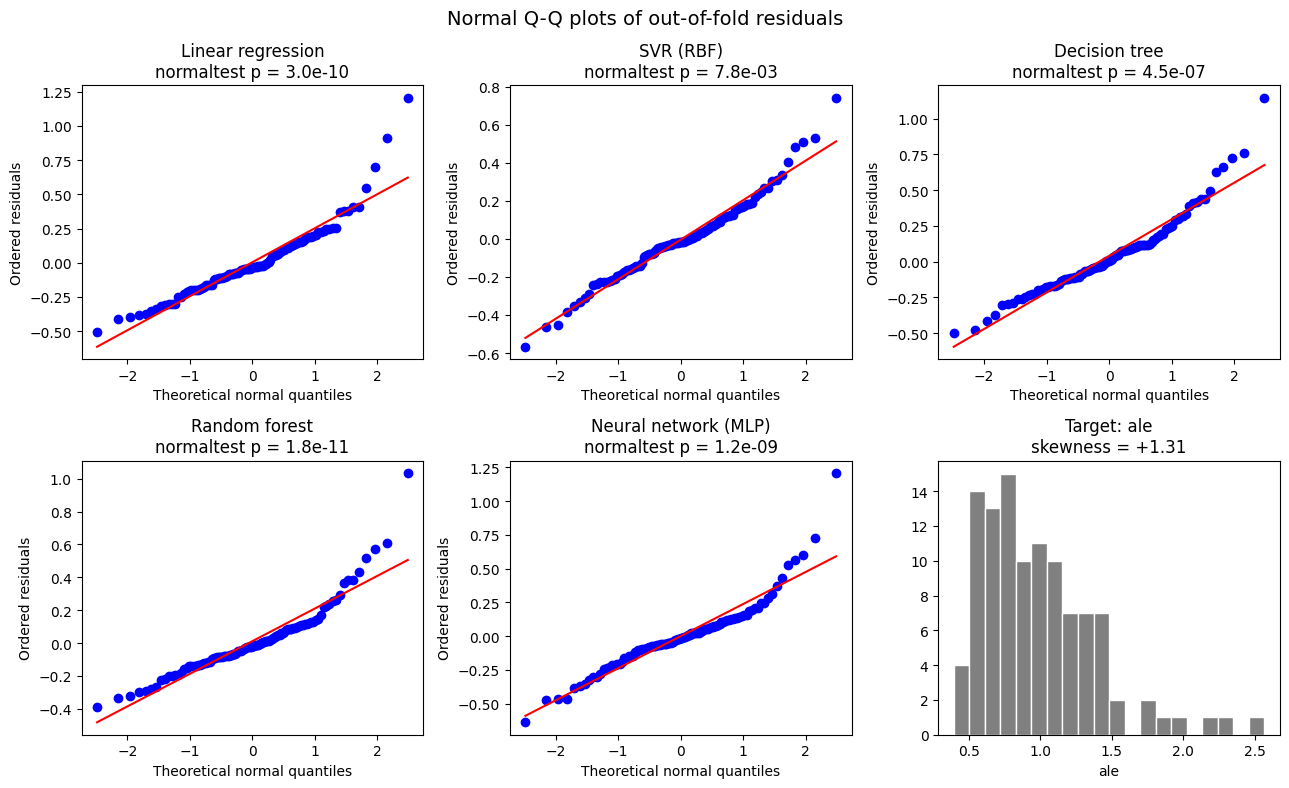

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, r) in zip(axes.flat, residuals.items()):
    stats.probplot(r, dist="norm", plot=ax)
    ax.set_title(f"{name}\nnormaltest p = {stats.normaltest(r).pvalue:.1e}")
    ax.set_xlabel("Theoretical normal quantiles")
    ax.set_ylabel("Ordered residuals")

ax = axes.flat[-1]
ax.hist(y, bins=20, color="gray", edgecolor="white")
ax.set_title(f"Target: ale\nskewness = {stats.skew(y):+.2f}")
ax.set_xlabel("ale")
fig.suptitle("Normal Q-Q plots of out-of-fold residuals", fontsize=14)
fig.tight_layout()
plt.show()

**A log-scale check.** `ale` is a positive error measure with a long right tail (histogram above), which suggests the noise may be multiplicative rather than additive. As an extra check, fit the same linear model to $\log(\text{ale})$ and test those residuals.

RMSE               0.195
skewness           0.307
excess kurtosis    0.246
normaltest p       0.286
Shapiro-Wilk p     0.502


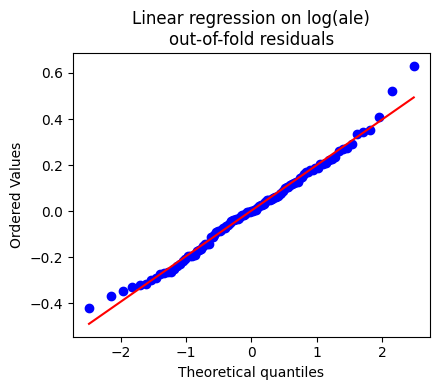

In [5]:
log_y = np.log(y)
r_log = log_y - cross_val_predict(LinearRegression(), X, log_y, cv=cv)
print(pd.Series(normality_summary(r_log)).round(3).to_string())

fig, ax = plt.subplots(figsize=(4.5, 4))
stats.probplot(r_log, dist="norm", plot=ax)
ax.set_title("Linear regression on log(ale)\nout-of-fold residuals")
fig.tight_layout()
plt.show()

**Results and conclusion.**

- **Every model rejects normality.** For all five models, both tests reject normality of the out-of-fold residuals at the 5% level. Most p-values are far below 0.05; the SVR comes closest to normal but is still rejected.
- **The departure is the same for every model.** The residuals have positive skewness and positive excess kurtosis. In the Q–Q plots the points follow the line in the middle but bend sharply upward in the right tail: a few observations have much larger `ale` than any model predicts. Changing the model class reduces the RMSE somewhat, but it doesn't remove these heavy right tails. That suggests the non-normality comes from the noise in the data, not from a poorly chosen model.
- **In-sample residuals can be misleading.** The decision tree's *in-sample* residuals pass both tests, while its out-of-fold residuals clearly fail. When a flexible model fits the training data closely, its in-sample residuals understate the real noise. That is why the out-of-fold residuals are the right ones to test.
- **The log scale tells a different story.** A linear model on $\log(\text{ale})$ gives out-of-fold residuals that are consistent with normality (both p-values well above 0.05). The errors look approximately log-normal: roughly normal *multiplicative* noise.

So for predicting `ale` on its original scale, the residuals are not approximately normal: they are skewed and heavy-tailed. This weakens the usual justification for squared error loss, which is sensitive to exactly these large residuals. Two alternatives are a heavier-tailed likelihood, such as the Student-$t$ loss in Problem 5, or modeling $\log(\text{ale})$, where squared error is well justified.

## Problem 5

**Question.** Use an automatic differentiation framework and its SGD optimizer to implement models with custom loss functions: logistic and probit regression on the Breast Cancer Wisconsin data, and linear regression with squared-error and Student-$t$ losses on the ALE data. Compare each to an sklearn baseline.

**Framework.** This solution uses **JAX** for automatic differentiation (`jax.value_and_grad`) and **optax** for the optimizer (`optax.sgd`).

**Shared setup.**

- **Features:** standardized with a `StandardScaler` fit on the training set only. SGD with one learning rate works poorly when features are on very different scales, and the breast-cancer features range from about $10^{-3}$ to $10^{3}$.
- **Training:** mini-batch SGD with a constant learning rate. The training set is reshuffled each epoch and split into mini-batches; each mini-batch gives one gradient step on the mean loss over that batch.
- **Initialization and seeds:** parameters start at zero, and all random seeds are fixed, so results are reproducible.

In [6]:
import jax
import jax.numpy as jnp
import optax
from jax.scipy.stats import norm, t as student_t
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.model_selection import train_test_split


def fit_sgd(loss_fn, params, X, y, learning_rate, epochs, batch_size, seed=0):
    # Minimize mean loss_fn(params, X_batch, y_batch) with mini-batch SGD (optax.sgd).
    # Returns the fitted parameters and the full-training-set loss after each epoch.
    optimizer = optax.sgd(learning_rate)
    opt_state = optimizer.init(params)

    @jax.jit
    def step(params, opt_state, xb, yb):
        grads = jax.grad(loss_fn)(params, xb, yb)  # automatic differentiation
        updates, opt_state = optimizer.update(grads, opt_state, params)
        return optax.apply_updates(params, updates), opt_state

    rng = np.random.default_rng(seed)
    n = len(y)
    history = []
    for _ in range(epochs):
        perm = rng.permutation(n)
        for start in range(0, n, batch_size):
            batch = perm[start:start + batch_size]
            params, opt_state = step(params, opt_state, X[batch], y[batch])
        history.append(float(loss_fn(params, X, y)))
    return params, history


def zero_params(n_features):
    return {"w": jnp.zeros(n_features), "b": jnp.array(0.0)}

### Classification: Breast Cancer Wisconsin

The data have 569 observations, 30 features and a binary label. They are split 80/20 into training and test sets, stratified by label. The baseline is sklearn's `LogisticRegression` (default settings, which include a mild L2 penalty), evaluated by test accuracy.

In [7]:
X_bc, y_bc = load_breast_cancer(return_X_y=True)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_bc, y_bc, test_size=0.2, random_state=0, stratify=y_bc
)
scaler_c = StandardScaler().fit(Xc_train)
Xc_train, Xc_test = scaler_c.transform(Xc_train), scaler_c.transform(Xc_test)

baseline_clf = LogisticRegression(max_iter=1000).fit(Xc_train, yc_train)
baseline_acc = accuracy_score(yc_test, baseline_clf.predict(Xc_test))
print(f"train / test sizes: {len(yc_train)} / {len(yc_test)}")
print(f"Baseline (sklearn LogisticRegression) test accuracy: {baseline_acc:.4f}")

train / test sizes: 455 / 114
Baseline (sklearn LogisticRegression) test accuracy: 0.9825


#### (a) Logistic regression

Model: $f(x_i) = \sigma(w^T x_i + b)$. Loss: binary cross-entropy,

$$L(y_i, f(x_i)) = -\big[\, y_i \log f(x_i) + (1 - y_i) \log(1 - f(x_i)) \,\big].$$

Before taking logs, the predicted probability is clipped to $[10^{-7},\, 1 - 10^{-7}]$, so $\log 0$ can never occur. Training uses SGD with learning rate $0.05$, batch size $32$ and $100$ epochs. A test observation is predicted as class 1 when $f(x_i) \ge 0.5$.

In [8]:
EPS = 1e-7


def binary_cross_entropy(p, y):
    p = jnp.clip(p, EPS, 1 - EPS)  # avoid log(0)
    return -jnp.mean(y * jnp.log(p) + (1 - y) * jnp.log(1 - p))


def logistic_model(params, X):
    return jax.nn.sigmoid(X @ params["w"] + params["b"])


def probit_model(params, X):
    return norm.cdf(X @ params["w"] + params["b"])


def classification_loss(model):
    return lambda params, X, y: binary_cross_entropy(model(params, X), y)


Xc_train_j, Xc_test_j = jnp.array(Xc_train), jnp.array(Xc_test)
yc_train_j = jnp.array(yc_train, dtype=jnp.float32)
clf_settings = dict(learning_rate=0.05, epochs=100, batch_size=32)


def test_accuracy(model, params):
    return accuracy_score(yc_test, np.asarray(model(params, Xc_test_j)) >= 0.5)


logit_params, logit_hist = fit_sgd(
    classification_loss(logistic_model), zero_params(30), Xc_train_j, yc_train_j, **clf_settings
)
logit_acc = test_accuracy(logistic_model, logit_params)
print(f"Logistic regression (JAX + SGD) test accuracy: {logit_acc:.4f}   (baseline {baseline_acc:.4f})")

Logistic regression (JAX + SGD) test accuracy: 0.9737   (baseline 0.9825)


#### (b) Probit regression

Model: $f(x_i) = \Phi(w^T x_i + b)$, where $\Phi$ is the standard normal CDF (`jax.scipy.stats.norm.cdf`). It uses the same clipped binary cross-entropy loss and the same SGD settings as (a).

In [9]:
probit_params, probit_hist = fit_sgd(
    classification_loss(probit_model), zero_params(30), Xc_train_j, yc_train_j, **clf_settings
)
probit_acc = test_accuracy(probit_model, probit_params)

n_test = len(yc_test)
clf_results = pd.DataFrame({
    "model": ["sklearn LogisticRegression (baseline)", "Logistic regression (JAX + SGD)",
              "Probit regression (JAX + SGD)"],
    "test accuracy": [baseline_acc, logit_acc, probit_acc],
})
clf_results["misclassified (of %d)" % n_test] = ((1 - clf_results["test accuracy"]) * n_test).round().astype(int)
clf_results["test accuracy"] = clf_results["test accuracy"].map("{:.4f}".format)
print(clf_results.to_string(index=False))

                                model test accuracy  misclassified (of 114)
sklearn LogisticRegression (baseline)        0.9825                       2
      Logistic regression (JAX + SGD)        0.9737                       3
        Probit regression (JAX + SGD)        0.9737                       3


**Comparison to the baseline.** Both SGD models match the sklearn baseline to within about one test observation. The table above gives the exact counts; with 114 test points, each misclassification moves accuracy by about 0.9 percentage points.

- **Logistic regression (a)** minimizes the same cross-entropy objective as sklearn. sklearn adds a small L2 penalty and solves the problem exactly (L-BFGS). The SGD model has no penalty, and after 100 epochs its training loss is still slowly decreasing (left panel of the training-curve plot below). That's typical when the classes are nearly separable: without a penalty, the cross-entropy keeps falling as $\|w\|$ grows. These differences change the weights but flip at most a borderline test case or two.
- **Probit regression (b)** gives essentially the same classifier. $\Phi$ and $\sigma$ are both S-shaped and nearly proportional near 0 ($\sigma(z) \approx \Phi(z / 1.7)$). They differ mainly in the tails, where the probit link approaches 0 and 1 faster. The predicted *probabilities* change a little, but the decision boundary $\{x : w^T x + b = 0\}$ is almost the same, so accuracy is too.
- **Overall:** the differences are within the noise of a 114-point test set. On this nearly linearly separable data, the link function and the optimizer barely matter.

### Regression: ALE

The ALE data (from Problem 4) are split 80/20 into training and test sets, with the same four features. The baseline is sklearn's `LinearRegression` (exact least squares), evaluated by test mean absolute error (MAE).

In [10]:
X_ale = ale[features].to_numpy()
y_ale = ale["ale"].to_numpy()
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_ale, y_ale, test_size=0.2, random_state=0)
scaler_r = StandardScaler().fit(Xr_train)
Xr_train, Xr_test = scaler_r.transform(Xr_train), scaler_r.transform(Xr_test)

baseline_reg = LinearRegression().fit(Xr_train, yr_train)
baseline_mae = mean_absolute_error(yr_test, baseline_reg.predict(Xr_test))
print(f"train / test sizes: {len(yr_train)} / {len(yr_test)}")
print(f"Baseline (sklearn LinearRegression) test MAE: {baseline_mae:.4f}")

train / test sizes: 85 / 22
Baseline (sklearn LinearRegression) test MAE: 0.1921


#### (a) Linear regression with squared-error loss

Model: $f(x_i) = w^T x_i + b$. Loss: $L(y_i, f(x_i)) = (y_i - f(x_i))^2$, averaged over each mini-batch. Training uses SGD with learning rate $0.01$, batch size $16$ and $500$ epochs.

In [11]:
def linear_model(params, X):
    return X @ params["w"] + params["b"]


def mse_loss(params, X, y):
    return jnp.mean((y - linear_model(params, X)) ** 2)


Xr_train_j, Xr_test_j, yr_train_j = jnp.array(Xr_train), jnp.array(Xr_test), jnp.array(yr_train)
reg_settings = dict(learning_rate=0.01, epochs=500, batch_size=16)


def test_mae(params):
    return mean_absolute_error(yr_test, np.asarray(linear_model(params, Xr_test_j)))


mse_params, mse_hist = fit_sgd(mse_loss, zero_params(4), Xr_train_j, yr_train_j, **reg_settings)
mse_mae = test_mae(mse_params)
print(f"Linear regression, MSE loss (JAX + SGD) test MAE: {mse_mae:.4f}   (baseline {baseline_mae:.4f})")

Linear regression, MSE loss (JAX + SGD) test MAE: 0.1919   (baseline 0.1921)


#### (b) Linear regression with Student-$t$ loss ($\nu = 5$)

Loss: the negative log-likelihood of the residual under a $t_5$ distribution,

$$L(y_i, f(x_i)) = -\log p\big(y_i - f(x_i),\, \nu = 5\big),$$

computed with `jax.scipy.stats.t.logpdf`. This uses the standard $t$ density from the problem, with scale fixed at 1. The SGD settings are the same as in (a).

In [12]:
NU = 5


def t_loss(params, X, y):
    residual = y - linear_model(params, X)
    return -jnp.mean(student_t.logpdf(residual, df=NU))


t_params, t_hist = fit_sgd(t_loss, zero_params(4), Xr_train_j, yr_train_j, **reg_settings)
t_mae = test_mae(t_params)
print(f"Linear regression, t(5) loss (JAX + SGD) test MAE: {t_mae:.4f}   (baseline {baseline_mae:.4f})")

Linear regression, t(5) loss (JAX + SGD) test MAE: 0.1897   (baseline 0.1921)


**Extra: $t$ loss with a learned scale.** With the scale fixed at 1, the $t_5$ loss is almost quadratic for residuals of the size seen here. The ALE residuals have a standard deviation of about $0.25$ (Problem 4), so $r^2/\nu$ is tiny and $\log(1 + r^2/\nu) \approx r^2/\nu$. The $t$ loss's heavy tails only start to matter for residuals large *relative to the scale*. To let the loss actually down-weight outliers, this variant learns the scale $s > 0$ jointly with $w$ and $b$, using the location–scale $t$ negative log-likelihood

$$L = -\log p\!\left(\frac{y_i - f(x_i)}{s},\, \nu = 5\right) + \log s,$$

parameterized by $\log s$ so that $s$ stays positive. This goes beyond what the problem asks; it's included because it explains the result in (b).

In [13]:
def t_loss_learned_scale(params, X, y):
    s = jnp.exp(params["log_s"])
    residual = y - linear_model(params, X)
    return -jnp.mean(student_t.logpdf(residual / s, df=NU) - jnp.log(s))


ts_init = {**zero_params(4), "log_s": jnp.array(0.0)}
ts_params, ts_hist = fit_sgd(t_loss_learned_scale, ts_init, Xr_train_j, yr_train_j, **reg_settings)
ts_mae = test_mae(ts_params)

coef_rows = {
    "sklearn LinearRegression (baseline)": (baseline_mae, baseline_reg.intercept_, baseline_reg.coef_),
    "MSE loss (JAX + SGD)": (mse_mae, mse_params["b"], mse_params["w"]),
    "t(5) loss, scale 1 (JAX + SGD)": (t_mae, t_params["b"], t_params["w"]),
    "t(5) loss, learned scale (extra)": (ts_mae, ts_params["b"], ts_params["w"]),
}
reg_results = pd.DataFrame(
    [[mae, float(b), *np.asarray(w)] for mae, b, w in coef_rows.values()],
    index=list(coef_rows), columns=["test MAE", "b"] + [f"w_{f}" for f in features],
)
with pd.option_context("display.width", 130, "display.float_format", "{:.4f}".format):
    print(reg_results)
print(f"\nlearned scale s = {float(jnp.exp(ts_params['log_s'])):.3f}")

                                     test MAE      b  w_anchor_ratio  w_trans_range  w_node_density  w_iterations
sklearn LinearRegression (baseline)    0.1921 1.0182         -0.0540        -0.0717         -0.2928       -0.2139
MSE loss (JAX + SGD)                   0.1919 1.0179         -0.0533        -0.0738         -0.2943       -0.2147
t(5) loss, scale 1 (JAX + SGD)         0.1897 1.0158         -0.0536        -0.0706         -0.2911       -0.2104
t(5) loss, learned scale (extra)       0.1674 0.9749         -0.0263        -0.0843         -0.2845       -0.1390

learned scale s = 0.170


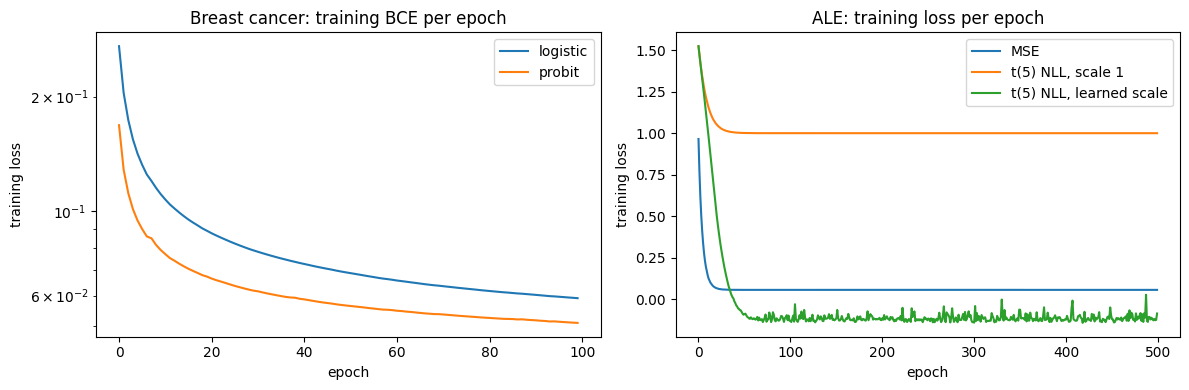

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(logit_hist, label="logistic")
axes[0].plot(probit_hist, label="probit")
axes[0].set(title="Breast cancer: training BCE per epoch", xlabel="epoch", ylabel="training loss", yscale="log")
axes[0].legend()
axes[1].plot(mse_hist, label="MSE")
axes[1].plot(t_hist, label="t(5) NLL, scale 1")
axes[1].plot(ts_hist, label="t(5) NLL, learned scale")
axes[1].set(title="ALE: training loss per epoch", xlabel="epoch", ylabel="training loss")
axes[1].legend()
fig.tight_layout()
plt.show()

**Comparison to the baseline.**

- **(a) MSE loss.** SGD on the squared-error loss recovers the least-squares fit: the intercept, coefficients and test MAE agree closely with sklearn's `LinearRegression`, which solves the same problem exactly. The small remaining differences come from stopping constant-step SGD after a fixed number of epochs (see Problem 3). The training-loss curves above (right panel) show that all three regression fits have converged. The learned-scale curve stays noisy because the step size is constant.
- **(b) $t_5$ loss, scale 1.** This gives nearly the same fit and test MAE as the baseline. That's expected, not a failure of the $t$ loss. With scale 1 and residuals around $0.25$, the $t_5$ negative log-likelihood is $\tfrac{\nu+1}{2}\log(1 + r^2/\nu) \approx \tfrac{\nu+1}{2\nu}\, r^2$, which is just a rescaled squared error. So the minimizer barely changes.
- **Extra: learned scale.** When the scale is learned ($s \approx 0.17$, comparable to the typical residual), the large residuals fall in the $t$ distribution's heavy tails and get much less weight. The fit is no longer pulled toward the few observations with unusually large `ale` that Problem 4 identified in the right tail. The intercept drops and the test MAE improves noticeably over the least-squares baseline.

**Caveat:** the test set has only 22 observations, so these MAE differences are suggestive rather than conclusive. Still, the direction agrees with Problem 4: the ALE residuals are skewed and heavy-tailed, so a robust, heavier-tailed likelihood is a better fit for this data than squared error.